In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

In [18]:

df = pd.read_csv("/content/04_student_performance.csv")


rename_map = {'school': 'school', 'sex': 'sex', 'age': 'age', 'address': 'home_area', 'famsize': 'family_size', 'Pstatus': 'parent_status', 'Medu': 'mother_education', 'Fedu': 'father_education', 'Mjob': 'mother_job', 'Fjob': 'father_job', 'reason': 'school_choice_reason', 'guardian': 'guardian', 'traveltime': 'travel_time', 'studytime': 'weekly_study_time', 'failures': 'past_class_failures', 'schoolsup': 'school_support', 'famsup': 'family_support', 'paid': 'extra_paid_classes', 'activities': 'extracurricular_activities', 'nursery': 'attended_nursery', 'higher': 'wants_higher_education', 'internet': 'internet_access', 'romantic': 'romantic_relationship', 'famrel': 'family_relationship_quality', 'freetime': 'free_time', 'goout': 'going_out', 'Dalc': 'workday_alcohol_use', 'Walc': 'weekend_alcohol_use', 'health': 'self_reported_health', 'absences': 'school_absences', 'G1': 'first_period_grade', 'G2': 'second_period_grade', 'G3': 'final_grade', 'course': 'course'}
df = df.rename(columns=rename_map)

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (1044, 34)


,school,sex,age,home_area,family_size,parent_status,mother_education,father_education,mother_job,father_job,...,free_time,going_out,workday_alcohol_use,weekend_alcohol_use,self_reported_health,school_absences,first_period_grade,second_period_grade,final_grade,course
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,3,4,1,1,3,6,5,6,6,mathematics
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,3,3,1,1,3,4,5,5,6,mathematics
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,3,2,2,3,3,10,7,8,10,mathematics
3,GP,F,15,U,GT3,T,4,2,health,services,...,2,2,1,1,5,2,15,14,15,mathematics
4,GP,F,16,U,GT3,T,3,3,other,other,...,3,2,1,2,5,4,6,10,10,mathematics


In [19]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nNumerical summary:")
display(df.describe().T)

Column names:
['school', 'sex', 'age', 'home_area', 'family_size', 'parent_status', 'mother_education', 'father_education', 'mother_job', 'father_job', 'school_choice_reason', 'guardian', 'travel_time', 'weekly_study_time', 'past_class_failures', 'school_support', 'family_support', 'extra_paid_classes', 'extracurricular_activities', 'attended_nursery', 'wants_higher_education', 'internet_access', 'romantic_relationship', 'family_relationship_quality', 'free_time', 'going_out', 'workday_alcohol_use', 'weekend_alcohol_use', 'self_reported_health', 'school_absences', 'first_period_grade', 'second_period_grade', 'final_grade', 'course']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1044 entries, 0 to 1043
Data columns (total 34 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   school                       1044 non-null   object
 1   sex                          1044 non-null   object
 2

,count,mean,std,min,25%,50%,75%,max
age,1044.0,16.726054,1.239975,15.0,16.0,17.0,18.0,22.0
mother_education,1044.0,2.603448,1.124907,0.0,2.0,3.0,4.0,4.0
father_education,1044.0,2.387931,1.099938,0.0,1.0,2.0,3.0,4.0
travel_time,1044.0,1.522989,0.731727,1.0,1.0,1.0,2.0,4.0
weekly_study_time,1044.0,1.970307,0.834353,1.0,1.0,2.0,2.0,4.0
past_class_failures,1044.0,0.264368,0.656142,0.0,0.0,0.0,0.0,3.0
family_relationship_quality,1044.0,3.935824,0.933401,1.0,4.0,4.0,5.0,5.0
free_time,1044.0,3.201149,1.031507,1.0,3.0,3.0,4.0,5.0
going_out,1044.0,3.156130,1.152575,1.0,2.0,3.0,4.0,5.0
workday_alcohol_use,1044.0,1.494253,0.911714,1.0,1.0,1.0,2.0,5.0


In [21]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nNumerical summary:")
display(df.describe().T)

Column names:
['school', 'sex', 'age', 'home_area', 'family_size', 'parent_status', 'mother_education', 'father_education', 'mother_job', 'father_job', 'school_choice_reason', 'guardian', 'travel_time', 'weekly_study_time', 'past_class_failures', 'school_support', 'family_support', 'extra_paid_classes', 'extracurricular_activities', 'attended_nursery', 'wants_higher_education', 'internet_access', 'romantic_relationship', 'family_relationship_quality', 'free_time', 'going_out', 'workday_alcohol_use', 'weekend_alcohol_use', 'self_reported_health', 'school_absences', 'first_period_grade', 'second_period_grade', 'final_grade', 'course']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1044 entries, 0 to 1043
Data columns (total 34 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   school                       1044 non-null   object
 1   sex                          1044 non-null   object
 2

,count,mean,std,min,25%,50%,75%,max
age,1044.0,16.726054,1.239975,15.0,16.0,17.0,18.0,22.0
mother_education,1044.0,2.603448,1.124907,0.0,2.0,3.0,4.0,4.0
father_education,1044.0,2.387931,1.099938,0.0,1.0,2.0,3.0,4.0
travel_time,1044.0,1.522989,0.731727,1.0,1.0,1.0,2.0,4.0
weekly_study_time,1044.0,1.970307,0.834353,1.0,1.0,2.0,2.0,4.0
past_class_failures,1044.0,0.264368,0.656142,0.0,0.0,0.0,0.0,3.0
family_relationship_quality,1044.0,3.935824,0.933401,1.0,4.0,4.0,5.0,5.0
free_time,1044.0,3.201149,1.031507,1.0,3.0,3.0,4.0,5.0
going_out,1044.0,3.156130,1.152575,1.0,2.0,3.0,4.0,5.0
workday_alcohol_use,1044.0,1.494253,0.911714,1.0,1.0,1.0,2.0,5.0


In [20]:
print("Missing values in each column:")
display(df.isnull().sum().sort_values(ascending=False))

print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values in each column:


,0
school,0
sex,0
age,0
home_area,0
family_size,0
parent_status,0
mother_education,0
father_education,0
mother_job,0
father_job,0


Total missing values: 0
Duplicate rows: 0


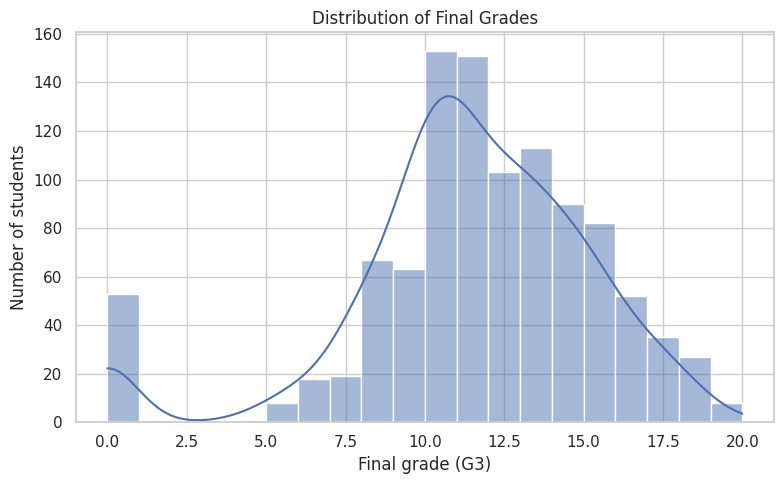

In [22]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="final_grade", bins=20, kde=True)
plt.title("Distribution of Final Grades")
plt.xlabel("Final grade (G3)")
plt.ylabel("Number of students")
plt.tight_layout()
plt.show()



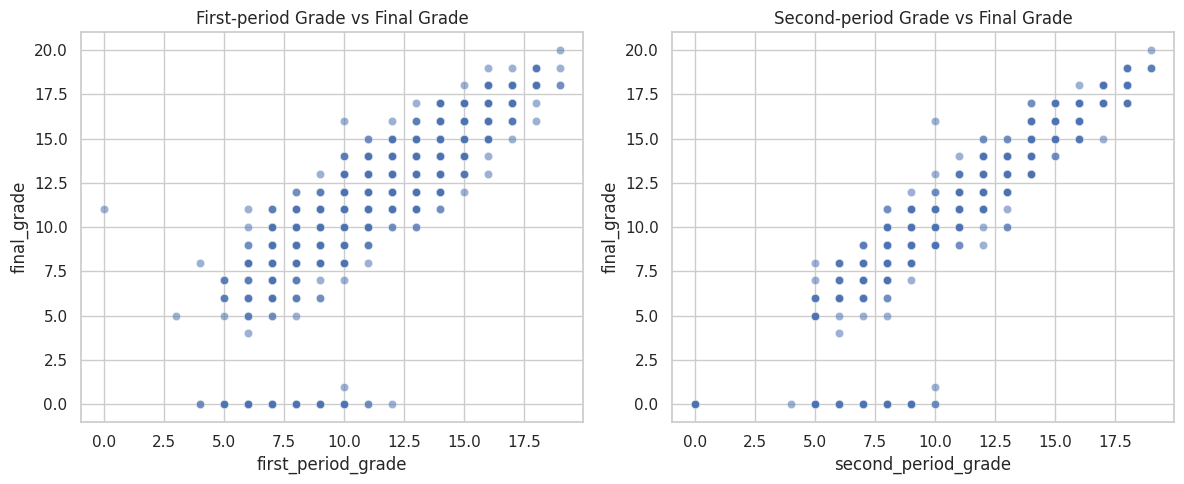

In [23]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.scatterplot(data=df, x="first_period_grade", y="final_grade", alpha=0.55, ax=axes[0])
axes[0].set_title("First-period Grade vs Final Grade")
sns.scatterplot(data=df, x="second_period_grade", y="final_grade", alpha=0.55, ax=axes[1])
axes[1].set_title("Second-period Grade vs Final Grade")
plt.tight_layout()
plt.show()

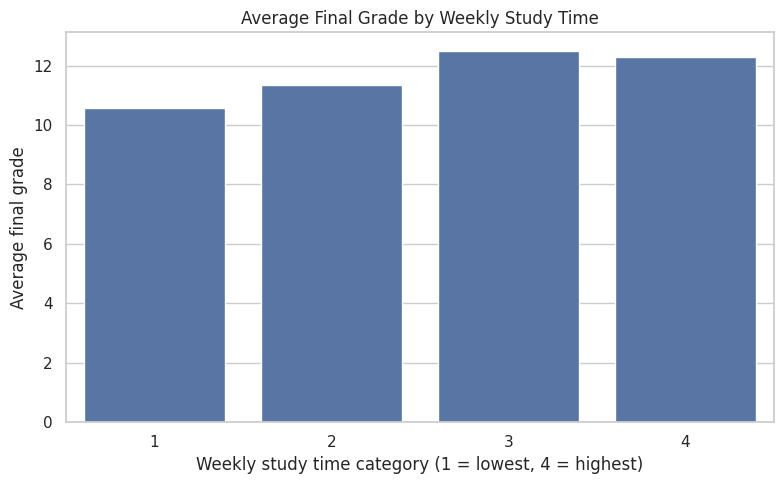

In [24]:

plt.figure(figsize=(8, 5))
sns.barplot(data=df, x="weekly_study_time", y="final_grade", errorbar=None)
plt.title("Average Final Grade by Weekly Study Time")
plt.xlabel("Weekly study time category (1 = lowest, 4 = highest)")
plt.ylabel("Average final grade")
plt.tight_layout()
plt.show()

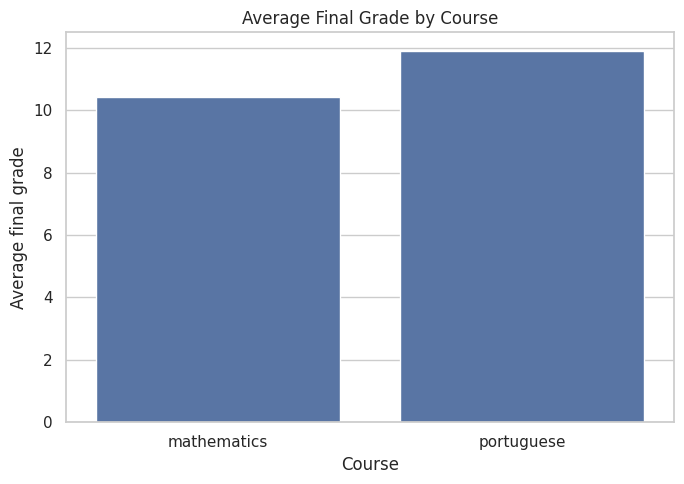

In [25]:
plt.figure(figsize=(7, 5))
sns.barplot(data=df, x="course", y="final_grade", errorbar=None)
plt.title("Average Final Grade by Course")
plt.xlabel("Course")
plt.ylabel("Average final grade")
plt.tight_layout()
plt.show()

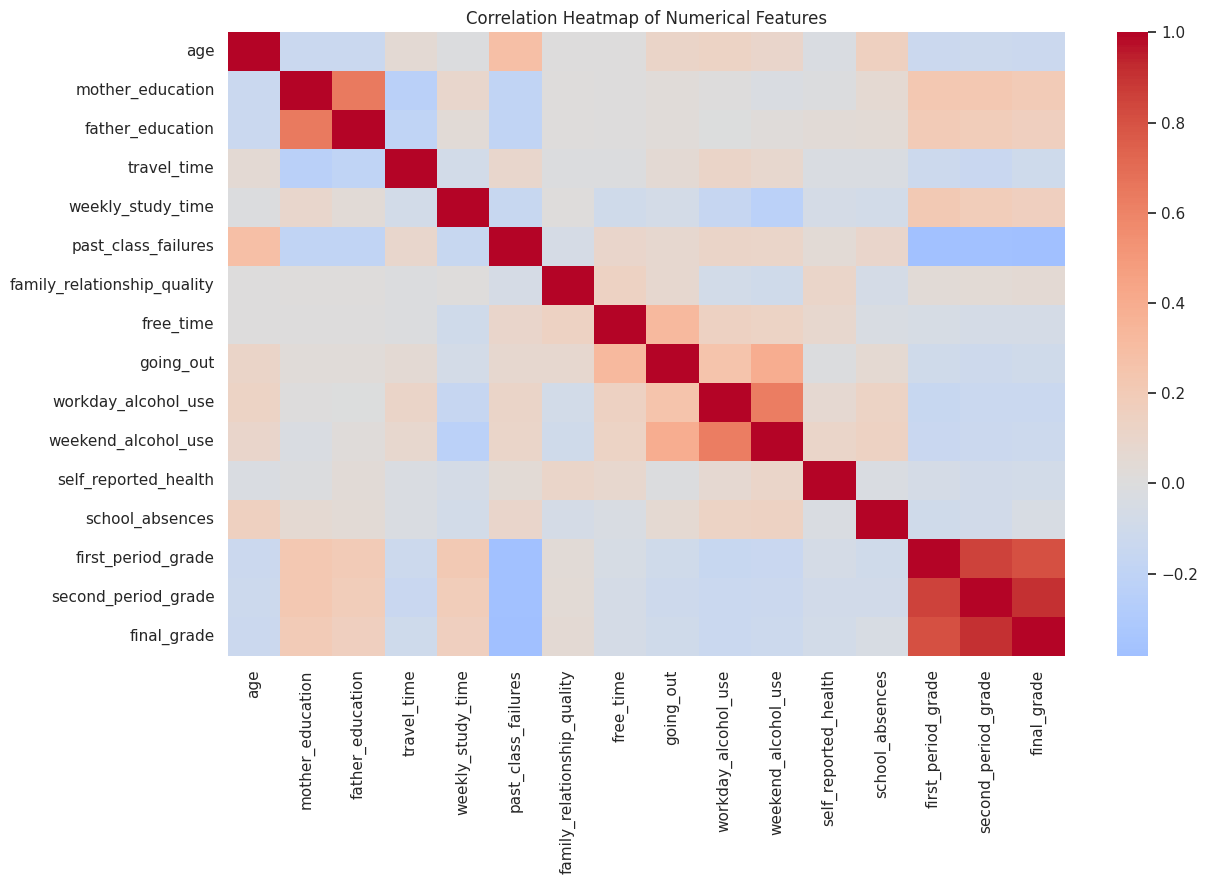

In [26]:
numeric_df = df.select_dtypes(include=np.number)
plt.figure(figsize=(13, 9))
sns.heatmap(numeric_df.corr(), cmap="coolwarm", center=0)
plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()


In [31]:
# X contains the input features. y contains the value we want to predict.
X = df.drop(columns=["final_grade"])
y = df["final_grade"]

categorical_features = X.select_dtypes(include=["object"]).columns.tolist()
numerical_features = X.select_dtypes(exclude=["object"]).columns.tolist()

print("Number of categorical features:", len(categorical_features))
print("Number of numerical features:", len(numerical_features))
print("Target variable:", y.name)

Number of categorical features: 18
Number of numerical features: 15
Target variable: final_grade


In [32]:
# Use capital X consistently: X_train and X_test.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 835
Testing rows: 209


In [33]:
def create_preprocessor():
    numerical_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor = ColumnTransformer(transformers=[
        ("num", numerical_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features)
    ])

    return preprocessor

In [34]:
linear_model = Pipeline(steps=[
    ("preprocessor", create_preprocessor()),
    ("regressor", LinearRegression())
])

linear_model.fit(X_train, y_train)
linear_predictions = linear_model.predict(X_test)

print("Linear Regression training and prediction completed.")

Linear Regression training and prediction completed.


In [36]:
random_forest_model = Pipeline(steps=[
    ("preprocessor", create_preprocessor()),
    ("regressor", RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

random_forest_model.fit(X_train, y_train)
random_forest_predictions = random_forest_model.predict(X_test)

print("Random Forest Regression training and prediction completed.")

Random Forest Regression training and prediction completed.


In [37]:
def calculate_metrics(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)
    return mae, rmse, r2

lr_mae, lr_rmse, lr_r2 = calculate_metrics(y_test, linear_predictions)
rf_mae, rf_rmse, rf_r2 = calculate_metrics(y_test, random_forest_predictions)

results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest Regression"],
    "MAE": [lr_mae, rf_mae],
    "RMSE": [lr_rmse, rf_rmse],
    "R2 Score": [lr_r2, rf_r2]
})

display(results.round(3))

,Model,MAE,RMSE,R2 Score
0,Linear Regression,1.017,1.760,0.800
1,Random Forest Regression,0.935,1.634,0.827


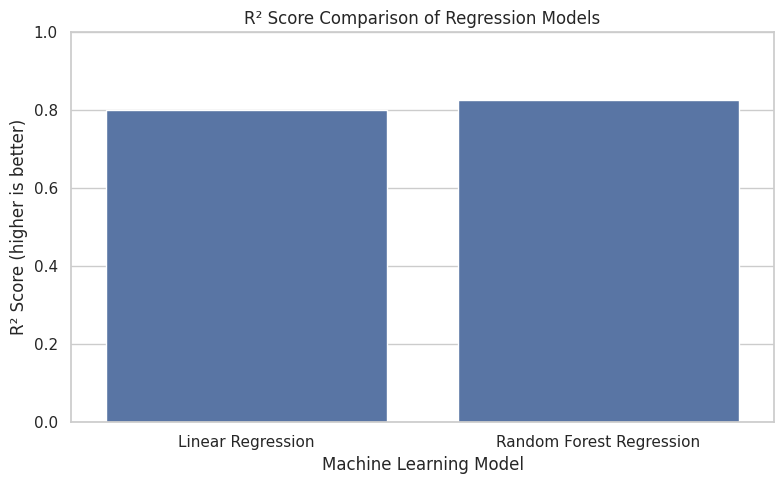

In [38]:
plt.figure(figsize=(8, 5))
sns.barplot(data=results, x="Model", y="R2 Score")
plt.title("R² Score Comparison of Regression Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("R² Score (higher is better)")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

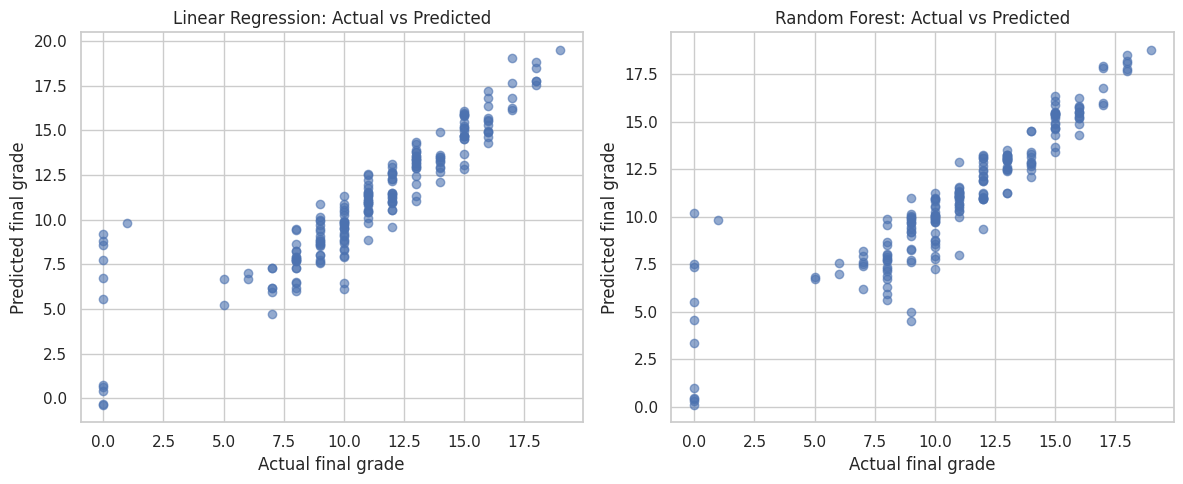

In [39]:
# Compare actual and predicted grades for both models.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(y_test, linear_predictions, alpha=0.6)
axes[0].set_title("Linear Regression: Actual vs Predicted")
axes[0].set_xlabel("Actual final grade")
axes[0].set_ylabel("Predicted final grade")

axes[1].scatter(y_test, random_forest_predictions, alpha=0.6)
axes[1].set_title("Random Forest: Actual vs Predicted")
axes[1].set_xlabel("Actual final grade")
axes[1].set_ylabel("Predicted final grade")

plt.tight_layout()
plt.show()

In [40]:
# Lower MAE means a smaller average absolute prediction error.
if lr_mae < rf_mae:
    best_model_name = "Linear Regression"
else:
    best_model_name = "Random Forest Regression"

print("Best model based on MAE:", best_model_name)

Best model based on MAE: Random Forest Regression


In [41]:
# Predict the final grade for one student from the test set.
sample_student = X_test.iloc[[0]]

print("Actual final grade:", y_test.iloc[0])
print("Linear Regression prediction:", round(linear_model.predict(sample_student)[0], 2))
print("Random Forest prediction:", round(random_forest_model.predict(sample_student)[0], 2))

Actual final grade: 11
Linear Regression prediction: 10.47
Random Forest prediction: 10.44
